Resolución FFT = 0.019531 Hz
Respiración = 9.375 BPM


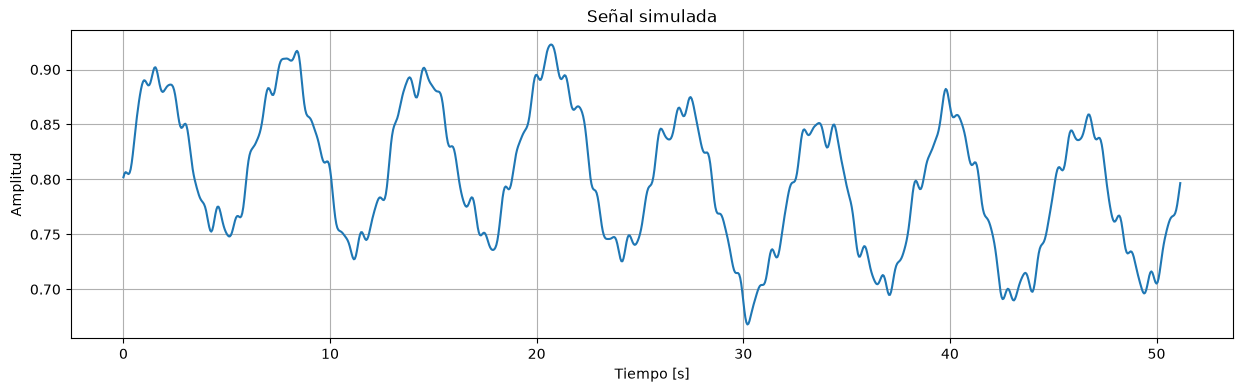

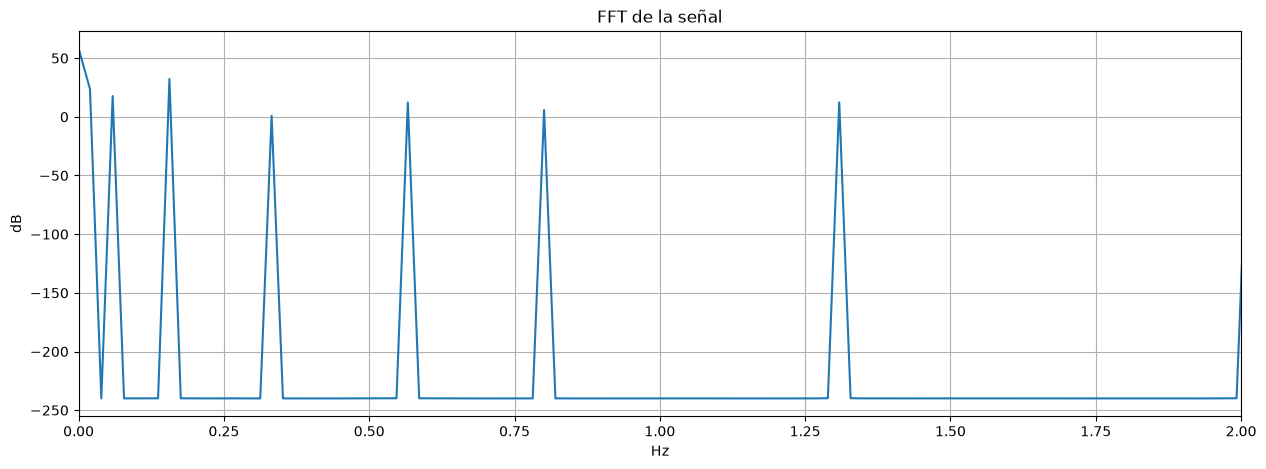

--------------------------------
Primera muestra : 0.8019626001562337
Última muestra  : 0.7966325693774426
Diferencia      : -0.005330030778791017
--------------------------------
--------------------------------
Error máximo : 1.5257066731888536e-05
RMSE         : 8.946049135907019e-06
--------------------------------


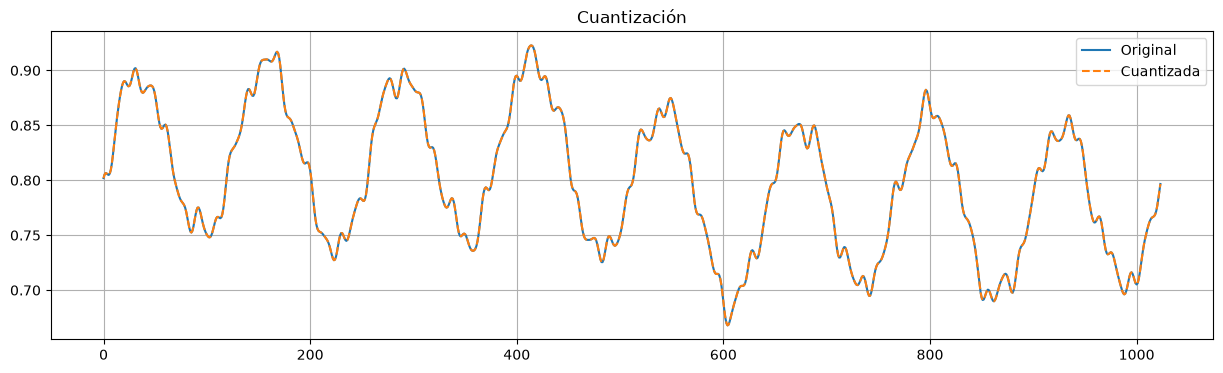

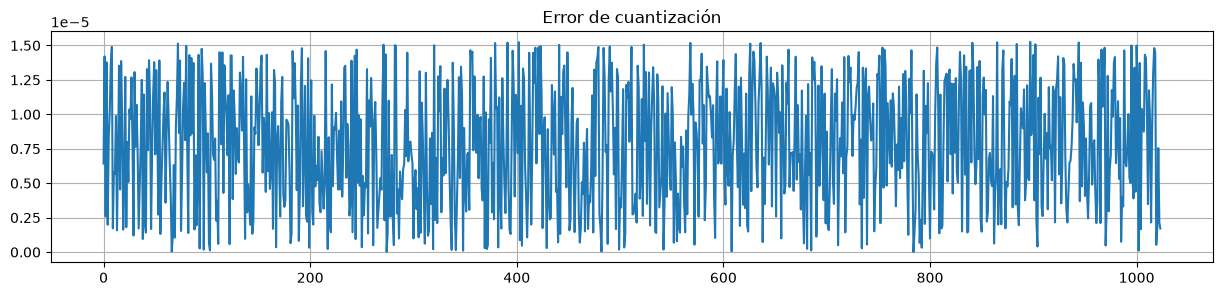

Archivo signal.mem generado correctamente.
--------------------------------
Máximo float : 0.9227772658234881
Mínimo float : 0.6679288114043697

Máximo entero : 60475
Mínimo entero : 43773
--------------------------------


In [7]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# PARÁMETROS
# ============================================================

Fs = 20.0                 # Hz
N = 1024                  # Potencia de 2
T = N/Fs                  # Duración total

BITS = 18
FRAC_BITS = 16            # Cambiar fácilmente

# ============================================================
# VECTOR DE TIEMPO
# ============================================================

t = np.arange(N)/Fs

# ============================================================
# RESOLUCIÓN ESPECTRAL
# ============================================================

df = Fs/N

print(f"Resolución FFT = {df:.6f} Hz")

# ============================================================
# CLUTTER
# ============================================================

DC = 0.80

clutter_slow = 0.03*np.sin(2*np.pi*(1*df)*t)

clutter = DC + clutter_slow

# ============================================================
# RESPIRACIÓN
# ============================================================

resp_bin = 8

resp_freq = resp_bin*df

print("Respiración =",resp_freq*60,"BPM")

resp = 0.08*np.sin(2*np.pi*resp_freq*t)

# ============================================================
# MICRO MOVIMIENTO
# ============================================================

body_bin = 3

body = 0.015*np.sin(2*np.pi*(body_bin*df)*t)

# ============================================================
# RUIDO PERIÓDICO
# ============================================================

noise_bins = [17,29,41,67,103]

noise = np.zeros(N)

np.random.seed(10)

for b in noise_bins:

    phase = 2*np.pi*np.random.rand()

    amp = np.random.uniform(0.002,0.01)

    noise += amp*np.sin(2*np.pi*(b*df)*t + phase)

# ============================================================
# SEÑAL FINAL
# ============================================================

signal = clutter + resp + body + noise

# ============================================================
# GRAFICAR
# ============================================================

plt.figure(figsize=(15,4))

plt.plot(t,signal)

plt.grid()

plt.title("Señal simulada")

plt.xlabel("Tiempo [s]")

plt.ylabel("Amplitud")

plt.show()

# ============================================================
# FFT
# ============================================================

FFT = np.fft.rfft(signal)

freq = np.fft.rfftfreq(N,1/Fs)

plt.figure(figsize=(15,5))

plt.plot(freq,20*np.log10(np.abs(FFT)+1e-12))

plt.grid()

plt.xlim(0,2)

plt.xlabel("Hz")

plt.ylabel("dB")

plt.title("FFT de la señal")

plt.show()

# ============================================================
# COMPROBAR PERIODICIDAD
# ============================================================

print("--------------------------------")
print("Primera muestra :",signal[0])
print("Última muestra  :",signal[-1])
print("Diferencia      :",signal[-1]-signal[0])
print("--------------------------------")

# ============================================================
# CUANTIZACIÓN CON _fixedInt.py
# ============================================================


# Cuantización de la señal
signal_fp = arrayFixedInt(BITS,
                          FRAC_BITS,
                          signal)

# Valores enteros almacenados
signal_int = np.array([x.value for x in signal_fp])

# Valores flotantes cuantizados (para comparar)
signal_quant = np.array([x.fValue for x in signal_fp])

#============================================================
# Comparación
#============================================================

error = signal - signal_quant

print("--------------------------------")
print("Error máximo :",np.max(np.abs(error)))
print("RMSE         :",np.sqrt(np.mean(error**2)))
print("--------------------------------")

plt.figure(figsize=(15,4))

plt.plot(signal,label="Original")

plt.plot(signal_quant,
         '--',
         label="Cuantizada")

plt.grid()

plt.legend()

plt.title("Cuantización")

plt.show()

plt.figure(figsize=(15,3))

plt.plot(error)

plt.grid()

plt.title("Error de cuantización")

plt.show()

# ============================================================
# GENERAR signal.mem
# ============================================================

with open("signal.mem","w") as f:

    for x in signal_q:

        if x<0:
            x=(1<<BITS)+x

        f.write("{:05X}\n".format(x))

print("Archivo signal.mem generado correctamente.")

# ============================================================
# VERIFICAR RANGO
# ============================================================

print("--------------------------------")
print("Máximo float :",np.max(signal))
print("Mínimo float :",np.min(signal))
print()

print("Máximo entero :",np.max(signal_q))
print("Mínimo entero :",np.min(signal_q))
print("--------------------------------")